# Задание 4 — переливание компота
## Q-learning и SARSA: награды, штрафы, графики и анимация

**Начальное состояние демонстрации: (2, 2, 0, 0)**.

**Цель** — распределить компот поровну: **(1, 1, 1, 1)**. 

**Награды:** −1 за допустимое поднятие, +100 дополнительно за достижение цели, −10 за недопустимую попытку, −20 дополнительно за исчерпание лимита шагов. Недопустимая попытка **не изменяет состояние** и **не считается фактическим поднятием**, но считается шагом эпизода.

**Особенность:** Агент может ошибаться, и мы наблюдаем, как меняется число ошибок по мере обучения. 

## Ответы на вопросы: 

### 1. Какая система наград и штрафов?

| Событие | Награда |
|---|---:|
| Допустимое поднятие стакана с переливанием | **−1** |
| Достижение целевого состояния | **+100 дополнительно** |
| Недопустимое действие | **−10** |
| Исчерпание лимита шагов без достижения цели | **−20 дополнительно** |

Таким образом, если последнее допустимое переливание приводит к цели, награда за этот шаг составляет −1 + 100 = +99. Недопустимая попытка не меняет объёмы жидкости, не считается фактическим поднятием, но учитывается как шаг. 

### 2. Как определить успешное завершение?

Успех наступает, когда во всех четырёх стаканах находится по 1 мл компота, то есть состояние становится **(1, 1, 1, 1)**. После достижения этого состояния агент получает бонус +100, а эпизод завершается. Если за 20 шагов цель не достигнута, эпизод завершается неуспешно с дополнительным штрафом −20.

### 3. Какими числами определяется состояние и сколько состояний? Что является состоянием?

**Состояние** — текущее распределение компота между четырьмя стаканами. Оно задаётся кортежем четырёх целых чисел (v1, v2, v3, v4), где vi — количество миллилитров в i-м стакане. Каждый объём принимает значение от **0 до 4**, причём всегда выполняется **v1 + v2 + v3 + v4 = 4**. Без ограничения на сумму имеется **5⁴ = 625** комбинаций, но при фиксированных 4 мл допустимо только **35 состояний**, включая целевое. Для начала эпизодов используются остальные **34 состояния**.

### 4. Что является действием?

**Действие** — выбор одного стакана-источника и объёмов, которые агент пытается перелить в каждый из четырёх стаканов. Оно задаётся массивом (i, q1, q2, q3, q4), где i — индекс источника от 0 до 3, а qj — запрошенный объём переливания в j-й стакан.

Например, (0, 0, 1, 1, 1) означает поднять первый стакан и перелить по 1 мл во второй, третий и четвёртый. Это **одно поднятие** с несколькими последовательными переливаниями.

Агент может выбрать и недопустимую попытку: перелить в источник, перелить нулевой объём, перелить больше доступного или переполнить получателя. Среда отклоняет такое действие, оставляет состояние без изменений и начисляет штраф −10. Для воспроизводимости объёмы переливания в данной модели задаются целыми миллилитрами.


## 1. Библиотеки и настройки

In [12]:
import itertools, random, os
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, HTML, Image

SEED=42
N_EPISODES=5000
N_RUNS=3
MAX_STEPS=20
ALPHA=0.20
GAMMA=0.95
EPS_START=1.0
EPS_END=0.02
EPS_DECAY=0.998
GOAL=(1,1,1,1)
DEMO_START=(2,2,0,0)
TOTAL=4
CAPACITY=4
R_LIFT=-1
R_SUCCESS=100
R_INVALID=-10
R_TIMEOUT=-20
random.seed(SEED)
np.random.seed(SEED)
print("Демонстрационный старт:", DEMO_START, "; цель:", GOAL, "; запусков:", N_RUNS, "; эпизодов на запуск:", N_EPISODES)

Демонстрационный старт: (2, 2, 0, 0) ; цель: (1, 1, 1, 1) ; запусков: 3 ; эпизодов на запуск: 5000


## 2. Состояния и действия

In [15]:
STATES=[s for s in itertools.product(range(5),repeat=4) if sum(s)==TOTAL]
STARTS=[s for s in STATES if s!=GOAL]
ACTIONS=[]
for src in range(4):
    recipients=[j for j in range(4) if j!=src]
    for amounts in itertools.product(range(5),repeat=3):
        q=[0]*4
        for j,v in zip(recipients,amounts): q[j]=v
        ACTIONS.append((src,*q))
    for v in range(1,5):
        q=[0]*4
        q[src]=v
        ACTIONS.append((src,*q))
ACTIONS=list(dict.fromkeys(ACTIONS))
ACTION_INDEX={a:i for i,a in enumerate(ACTIONS)}
print("Состояний:",len(STATES),"Начальных состояний:",len(STARTS),"Действий:",len(ACTIONS))
assert len(STATES)==35 and len(STARTS)==34

def apply_action(state,action):
    src,*q=action
    if q[src]!=0: return state,False,"переливание в источник"
    if sum(q)==0: return state,False,"нулевое переливание"
    if sum(q)>state[src]: return state,False,"недостаточно жидкости в источнике"
    if any(state[j]+q[j]>CAPACITY for j in range(4) if j!=src):
        return state,False,"переполнение получателя"
    new=list(state)
    new[src]-=sum(q)
    for j in range(4): new[j]+=q[j]
    new=tuple(new)
    assert sum(new)==TOTAL and all(0<=v<=CAPACITY for v in new)
    return new,True,""

for s,a in [
    (DEMO_START, (0,0,0,1,0)),   # допустимо: 1 мл из первого в третий
    (DEMO_START, (0,0,0,3,0)),   # недопустимо: в источнике 2 мл
    (DEMO_START, (0,1,0,0,0)),   # недопустимо: в источник переливать нельзя
]:
    print(s,a,"=>",apply_action(s,a))

Состояний: 35 Начальных состояний: 34 Действий: 516
(2, 2, 0, 0) (0, 0, 0, 1, 0) => ((1, 2, 1, 0), True, '')
(2, 2, 0, 0) (0, 0, 0, 3, 0) => ((2, 2, 0, 0), False, 'недостаточно жидкости в источнике')
(2, 2, 0, 0) (0, 1, 0, 0, 0) => ((2, 2, 0, 0), False, 'переливание в источник')


## 3. Среда и система наград

In [18]:
class CompoteEnv:
    def __init__(self): self.reset(DEMO_START)
    def reset(self,start=None):
        self.state=tuple(start if start is not None else random.choice(STARTS))
        self.steps=0; self.lifts=0; self.invalid=0
        return self.state
    def step(self,action):
        self.steps+=1
        nxt,valid,reason=apply_action(self.state,action)
        if valid:
            self.state=nxt; self.lifts+=1
            success=self.state==GOAL
            reward=R_LIFT+(R_SUCCESS if success else 0)
        else:
            self.invalid+=1
            success=False
            reward=R_INVALID
        done=success or self.steps>=MAX_STEPS
        if done and not success: reward+=R_TIMEOUT
        info=dict(valid=valid,reason=reason,success=success,timeout=done and not success)
        return self.state,reward,done,info

env=CompoteEnv()
env.reset(DEMO_START)
print("Успешное действие:",env.step((0,0,0,1,0)))
env.reset(DEMO_START)
print("Недопустимое действие:",env.step((0,0,0,3,0)))

Успешное действие: ((1, 2, 1, 0), -1, False, {'valid': True, 'reason': '', 'success': False, 'timeout': False})
Недопустимое действие: ((2, 2, 0, 0), -10, False, {'valid': False, 'reason': 'недостаточно жидкости в источнике', 'success': False, 'timeout': False})


## 4. Алгоритмы Q-learning и SARSA

**Q-learning** оценивает действие, ориентируясь на лучший возможный следующий шаг.

**SARSA** учитывает следующее действие, которое агент действительно выбрал, в том числе если оно оказалось неудачным.

Из-за большого количества возможных, но недопустимых попыток используются несколько тысяч эпизодов. Отдельно измеряем ошибки, успешность и число фактических поднятий.

In [22]:
def eps_at(ep): return max(EPS_END,EPS_START*(EPS_DECAY**ep))

def choose(Q,s,eps,rng):
    if rng.random()<eps: return rng.randrange(len(ACTIONS))
    vals=Q[s]
    return int(rng.choice(np.flatnonzero(vals==np.max(vals))))

def train(method,seed):
    rng=random.Random(seed)
    Q=defaultdict(lambda:np.zeros(len(ACTIONS),dtype=np.float32))
    env=CompoteEnv()
    records=[]
    for ep in range(N_EPISODES):
        s=env.reset(rng.choice(STARTS))
        eps=eps_at(ep)
        a=choose(Q,s,eps,rng)
        reward_sum=0.
        for step in range(MAX_STEPS):
            ns,r,done,info=env.step(ACTIONS[a])
            reward_sum+=r
            if method=="Q-learning":
                target=r if done else r+GAMMA*float(np.max(Q[ns]))
                Q[s][a]+=ALPHA*(target-Q[s][a])
                if done: break
                s=ns
                a=choose(Q,s,eps,rng)
            else:
                if done:
                    Q[s][a]+=ALPHA*(r-Q[s][a])
                    break
                na=choose(Q,ns,eps,rng)
                target=r+GAMMA*float(Q[ns][na])
                Q[s][a]+=ALPHA*(target-Q[s][a])
                s,a=ns,na
        records.append(dict(episode=ep+1,reward=reward_sum,success=int(env.state==GOAL),
                            lifts=env.lifts,invalid=env.invalid,epsilon=eps))
    return Q,pd.DataFrame(records)

RUNS={}
for method in ["Q-learning","SARSA"]:
    RUNS[method]=[]
    for k in range(N_RUNS):
        q,h=train(method,SEED+100*k+(0 if method=="Q-learning" else 1))
        RUNS[method].append((q,h))
        print(method,"запуск",k+1,"готов")

Q-learning запуск 1 готов
Q-learning запуск 2 готов
Q-learning запуск 3 готов
SARSA запуск 1 готов
SARSA запуск 2 готов
SARSA запуск 3 готов


SARSA запуск 1 готов
SARSA запуск 2 готов


SARSA запуск 3 готов


## 5. Кривые обучения: награда, успешность, ошибки, поднятия

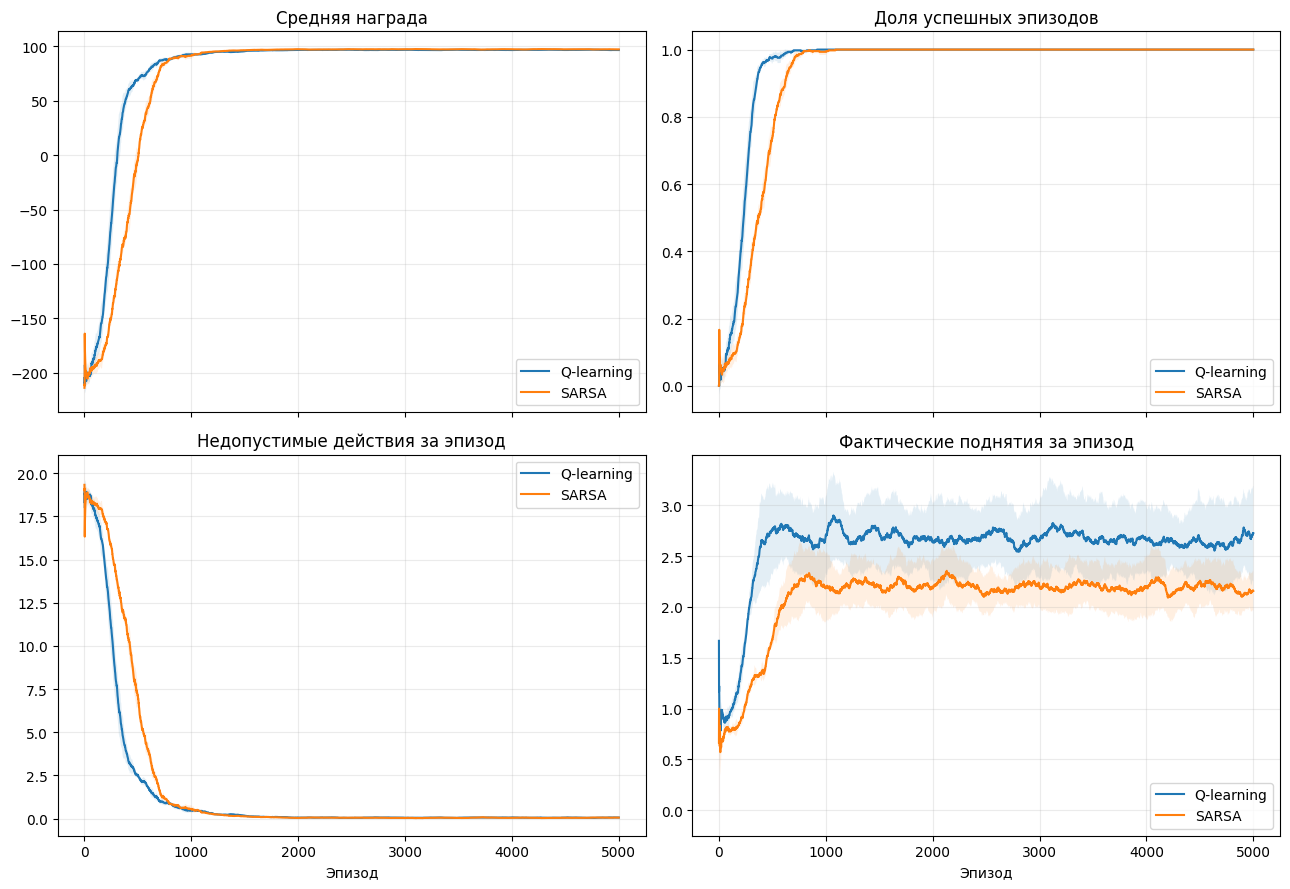

In [33]:
WINDOW=150
fig,axes=plt.subplots(2,2,figsize=(13,9),sharex=True)
for ax,(column,title) in zip(axes.ravel(),[
    ("reward","Средняя награда"),("success","Доля успешных эпизодов"),
    ("invalid","Недопустимые действия за эпизод"),("lifts","Фактические поднятия за эпизод")]):
    for method in RUNS:
        arr=np.stack([h[column].rolling(WINDOW,min_periods=1).mean().to_numpy()
                      for _,h in RUNS[method]])
        x=np.arange(1,N_EPISODES+1)
        avg=arr.mean(axis=0); std=arr.std(axis=0)
        ax.plot(x,avg,label=method)
        ax.fill_between(x,avg-std,avg+std,alpha=.12)
    ax.set_title(title); ax.grid(alpha=.25); ax.legend()
for ax in axes[-1]: ax.set_xlabel("Эпизод")
plt.tight_layout()
plt.show()

## 6. Проверка обученной политики

Для каждого состояния необходимо поднять каждый стакан, содержащий больше 1 мл. Поэтому минимум полезных поднятий равен числу таких стаканов. Проверяем, достигает ли обученная политика этого ориентира.

In [28]:
def evaluate(Q,start,return_path=False):
    env=CompoteEnv(); s=env.reset(start)
    path=[s]; actions=[]; reward_sum=0.
    for step in range(MAX_STEPS):
        a=int(np.argmax(Q[s]))
        ns,r,done,info=env.step(ACTIONS[a])
        actions.append((ACTIONS[a],r,info))
        reward_sum+=r; path.append(ns); s=ns
        if done: break
    result=dict(success=int(s==GOAL),reward=reward_sum,lifts=env.lifts,
                invalid=env.invalid,steps=env.steps,
                theoretical_min=sum(v>1 for v in start))
    result["optimal"]=int(result["success"] and result["lifts"]==result["theoretical_min"])
    return (result,path,actions) if return_path else result

rows=[]
for method,items in RUNS.items():
    for run,(Q,h) in enumerate(items,1):
        for s in STARTS:
            rows.append(dict(method=method,run=run,start=s,**evaluate(Q,s)))
test=pd.DataFrame(rows)
summary=test.groupby("method").agg(
    success_rate=("success","mean"),optimal_rate=("optimal","mean"),
    avg_reward=("reward","mean"),avg_lifts=("lifts","mean"),
    avg_invalid=("invalid","mean"),avg_steps=("steps","mean")
)
display(summary.round(3))
print("Средний теоретический минимум поднятий:",
      np.mean([sum(v>1 for v in s) for s in STARTS]))

,success_rate,optimal_rate,avg_reward,avg_lifts,avg_invalid,avg_steps
method,,,,,,
Q-learning,1.0,0.206,97.324,2.676,0.0,2.676
SARSA,1.0,0.333,97.814,2.186,0.0,2.186


Средний теоретический минимум поднятий: 1.1764705882352942


## 7. Пошаговая визуализация всех переливаний

Q-learning: старт=(2, 2, 0, 0), успех=True, поднятий=3, ошибок=0, награда=+97
Шаг 1: источник №2; №1 ← 2 мл; (2, 2, 0, 0) → (4, 0, 0, 0); награда -1; допустимо
Шаг 2: источник №1; №3 ← 1 мл; (4, 0, 0, 0) → (3, 0, 1, 0); награда -1; допустимо
Шаг 3: источник №1; №2 ← 1 мл, №4 ← 1 мл; (3, 0, 1, 0) → (1, 1, 1, 1); награда +99; допустимо


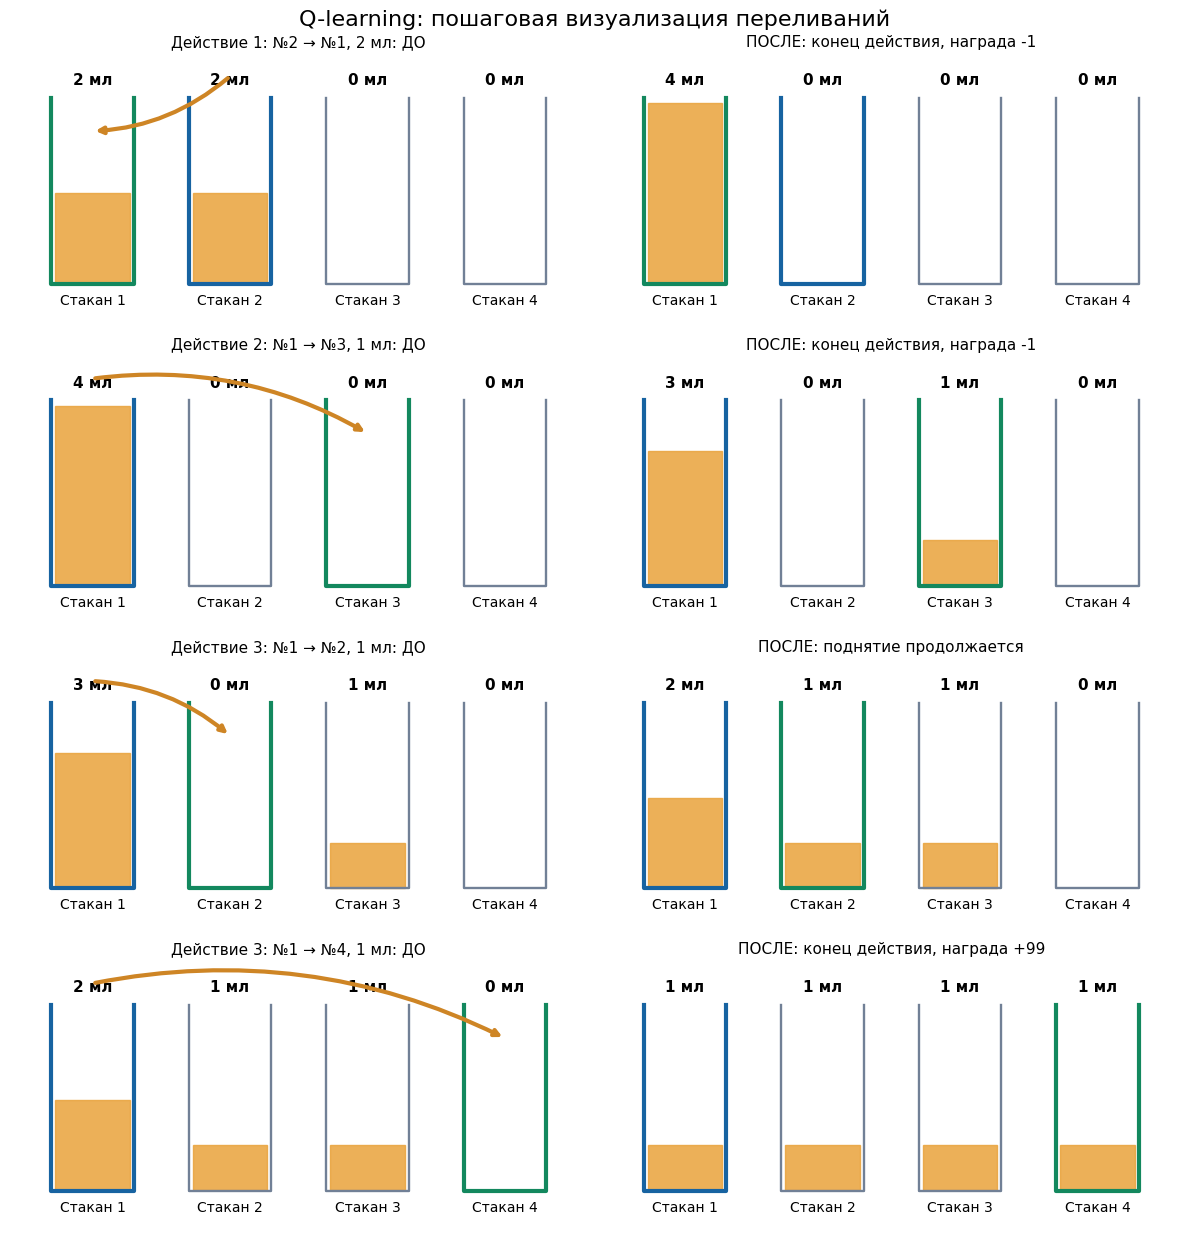

Показано 4 отдельных переливаний/ошибок в 3 действиях

SARSA: старт=(2, 2, 0, 0), успех=True, поднятий=2, ошибок=0, награда=+98
Шаг 1: источник №2; №1 ← 1 мл, №4 ← 1 мл; (2, 2, 0, 0) → (3, 0, 0, 1); награда -1; допустимо
Шаг 2: источник №1; №2 ← 1 мл, №3 ← 1 мл; (3, 0, 0, 1) → (1, 1, 1, 1); награда +99; допустимо


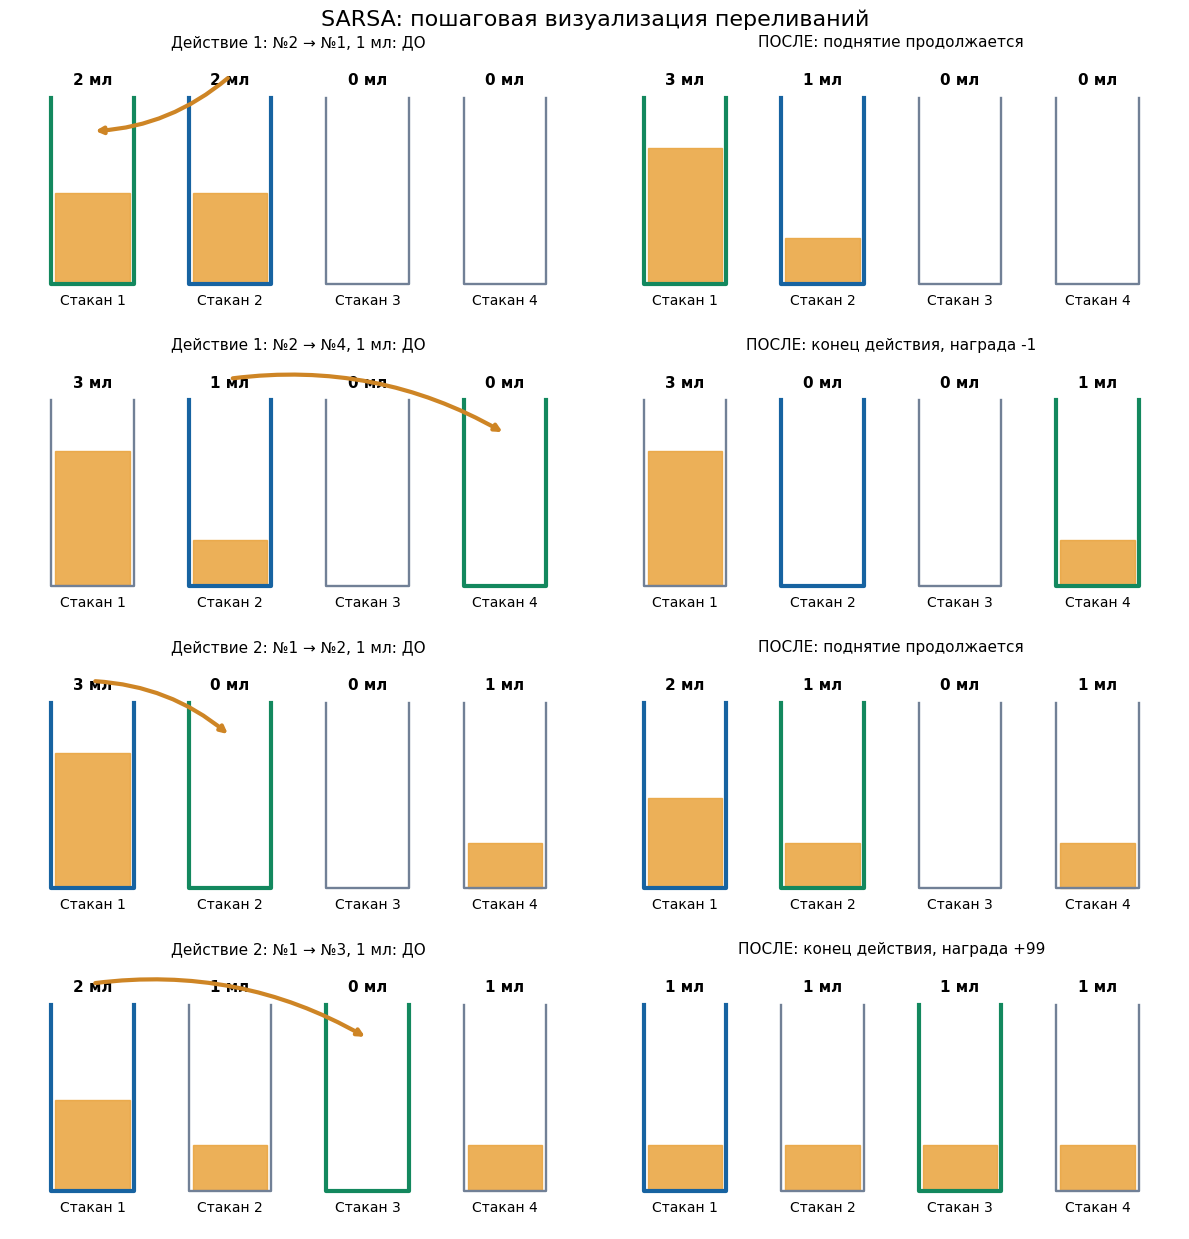

Показано 4 отдельных переливаний/ошибок в 2 действиях



In [39]:
from matplotlib.patches import Rectangle
from IPython.display import display, HTML

def best_Q(method):
    scored=[(np.mean([evaluate(Q,s)["reward"] for s in STARTS]),Q) for Q,_ in RUNS[method]]
    return max(scored,key=lambda x:x[0])[1]

def draw_cups(ax, levels, source=None, target=None, pouring=False):
    ax.set_xlim(-.1,4.1); ax.set_ylim(-.5,5.1); ax.axis("off")
    for j,volume in enumerate(levels):
        x=j+.5
        col="#1763a1" if j==source else ("#13885e" if j==target else "#718096")
        ax.plot([x-.30,x-.30,x+.30,x+.30],[4.2,.3,.3,4.2],
                lw=3 if j in (source,target) else 1.7,color=col)
        if volume>0:
            ax.add_patch(Rectangle((x-.27,.32),.54,volume*.94,color="#e9a33b",alpha=.85))
        ax.text(x,-.12,f"Стакан {j+1}",ha="center",fontsize=10)
        ax.text(x,4.48,f"{volume:g} мл",ha="center",fontsize=11,weight="bold")
    if pouring and source is not None and target is not None:
        ax.annotate("",xy=(target+.5,3.5),xytext=(source+.5,4.65),
                    arrowprops=dict(arrowstyle="-|>",color="#ce8525",lw=3,
                                    connectionstyle="arc3,rad=-0.17"))

def get_path(method,start=DEMO_START):
    result,path,actions=evaluate(best_Q(method),start,True)
    print(f"{method}: старт={start}, успех={bool(result['success'])}, "
          f"поднятий={result['lifts']}, ошибок={result['invalid']}, награда={result['reward']:+g}")
    for k,(action,r,info) in enumerate(actions,1):
        src,*q=action
        recipients=", ".join(f"№{j+1} ← {v} мл" for j,v in enumerate(q) if v)
        print(f"Шаг {k}: источник №{src+1}; {recipients or 'нет получателей'}; "
              f"{path[k-1]} → {path[k]}; награда {r:+g}; "
              f"{'допустимо' if info['valid'] else 'ОШИБКА: '+info['reason']}")
    return path,actions

def substeps(path,actions):
    #Разворачивает действия в отдельные переливания, не добавляя наград за каждое
    result=[]
    for k,(action,r,info) in enumerate(actions,1):
        src,*q=action
        before=tuple(path[k-1])
        if not info['valid']:
            result.append((k,src,None,0,before,before,r,False,info['reason'],True))
            continue
        current=list(before)
        transfers=[(dst,v) for dst,v in enumerate(q) if v>0]
        for idx,(dst,amount) in enumerate(transfers):
            old=tuple(current)
            current[src]-=amount
            current[dst]+=amount
            new=tuple(current)
            last=idx==len(transfers)-1
            result.append((k,src,dst,amount,old,new,r,True,'',last))
        assert tuple(current)==tuple(path[k]), (k,current,path[k])
    return result

def show_stepwise(method, path, actions):
    pieces = substeps(path, actions)
    if not pieces:
        print("Нет действий для визуализации")
        return

    fig, axs = plt.subplots(
        len(pieces), 2,
        figsize=(12, 3.15 * len(pieces)),
        squeeze=False
    )

    for row, (k, src, dst, amount, before, after,
              reward, valid, reason, last) in enumerate(pieces):
        draw_cups(axs[row, 0], before, src, dst, valid)
        draw_cups(axs[row, 1], after, src, dst)
        if valid:
            title = f"Действие {k}: №{src+1} → №{dst+1}, {amount} мл"
            end_text = (f"ПОСЛЕ: конец действия, награда {reward:+g}"
                        if last else "ПОСЛЕ: поднятие продолжается")
        else:
            title = f"Действие {k}: НЕДОПУСТИМО — {reason}"
            end_text = f"ПОСЛЕ: объёмы не изменились, награда {reward:+g}"
        axs[row, 0].set_title(title + ": ДО", fontsize=11)
        axs[row, 1].set_title(end_text, fontsize=11)

    fig.suptitle(f"{method}: пошаговая визуализация переливаний", fontsize=16)
    fig.tight_layout()
    plt.show()
    print(f"Показано {len(pieces)} отдельных переливаний/ошибок в {len(actions)} действиях")
    print()

paths={}
for method in RUNS:
    path,actions=get_path(method,start=DEMO_START)
    paths[method]=(path,actions)
    show_stepwise(method,path,actions)

## 8. Анимация переливания

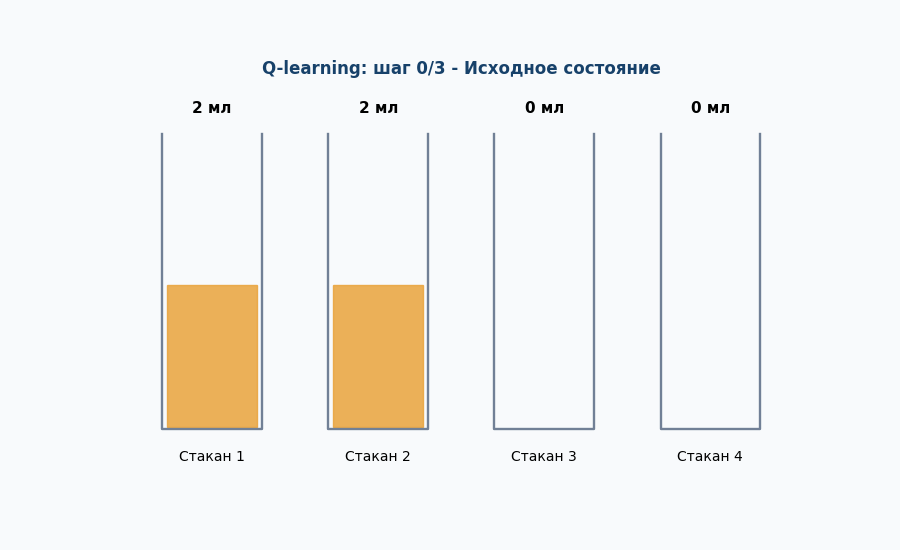

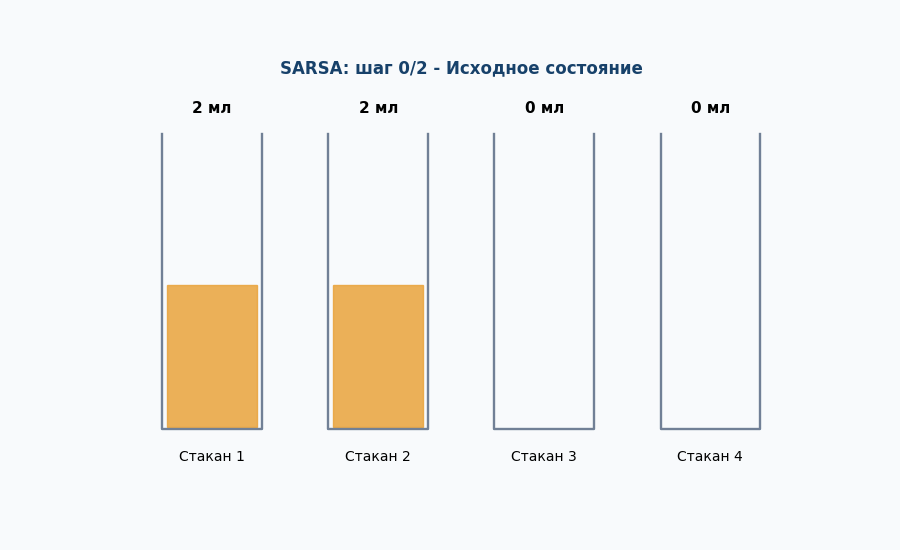

In [48]:
from io import BytesIO
from PIL import Image as PILImage
from IPython.display import Image, display

def make_frames(path, actions):
    frames = []
    def add(levels, step, phase, src=None, dst=None, action=None, reward=None, stream=False, n=1):
        frame = (np.array(levels, dtype=float).copy(), step, phase, src, dst, action, reward, stream)
        frames.extend([frame] * n)
    add(path[0], 0, "Исходное состояние", n=7)
    for k, (action, reward, info) in enumerate(actions, 1):
        src, *q = action
        levels = np.array(path[k-1], dtype=float)
        if not info["valid"]:
            add(levels, k, "НЕДОПУСТИМО: " + info["reason"], 
                src=src, action=action, reward=reward, n=12)
            continue
        # Поднятие стакана
        add(levels, k, f"Поднимаем стакан №{src+1}", 
            src=src, action=action, reward=reward, n=7)
        # Последовательное переливание
        for dst, amount in enumerate(q):
            if not amount:
                continue
            for t in np.linspace(0, 1, 11):
                now = levels.copy()
                now[src] -= amount * t
                now[dst] += amount * t
                add(now, k, f"Переливаем {amount} мл: №{src+1} → №{dst+1}",
                    src=src, dst=dst, action=action, reward=reward, stream=True)
            levels[src] -= amount
            levels[dst] += amount
            add(levels, k,f"В стакан №{dst+1} перелито {amount} мл",
                src=src, dst=dst, action=action, reward=reward, n=3)
        # Результат действия
        end = ("ЦЕЛЬ ДОСТИГНУТА" if tuple(path[k]) == GOAL else "Шаг завершён")
        add(path[k], k, end,
            src=src, action=action, reward=reward, n=9)
    # Итоговое состояние
    add(path[-1], len(actions), "Итоговое распределение", n=10)
    return frames

def show_animation(method, path, actions):
    frames = make_frames(path, actions)
    fig, ax = plt.subplots(figsize=(9, 5.5))
    fig.patch.set_facecolor("#f8fafc")
    gif_frames = []
    for k in range(len(frames)):
        levels, step, phase, src, dst, action, reward, stream = frames[k]
        ax.clear()
        draw_cups(ax, levels, src, dst, stream)
        ax.text(
            2, 5.0,
            f"{method}: шаг {step}/{len(actions)} - {phase}",
            ha="center",
            fontsize=12,
            weight="bold",
            color="#17416a"
        )
        if action is not None:
            s, *q = action
            receivers = ", ".join(f"№{j+1}: {v} мл" for j, v in enumerate(q) if v)
            ax.text(
                2, -0.40,
                f"Источник №{s+1} · "
                f"{receivers or 'нет получателей'}"
                f" · награда {reward:+g}",
                ha="center",
                fontsize=9
            )
        # Преобразуем рисунок в кадр GIF
        fig.canvas.draw()
        image = PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba()).copy())
        gif_frames.append(image.convert("RGB"))
    plt.close(fig)

    # Создаём GIF в памяти, не сохраняя файл
    buffer = BytesIO()

    gif_frames[0].save(
        buffer,
        format="GIF",
        save_all=True,
        append_images=gif_frames[1:],
        duration=170,
        loop=0,
        optimize=True
    )

    display(Image(data=buffer.getvalue(), format="gif"))

# Анимации Q-learning и SARSA
for method in RUNS:
    path, actions = paths[method]
    show_animation(method, path, actions)
    print()

## 9. Сравнение алгоритмов

Сравнение всех 34 нетерминальных состояний приведено в разделе 6. Здесь отдельно сравниваются две **показанные выше траектории** из выбранного начального состояния.

In [51]:
demo_rows=[]
for method in RUNS:
    result,path,actions=evaluate(best_Q(method),DEMO_START,True)
    demo_rows.append({
        "Алгоритм":method,
        "Начальное состояние":str(DEMO_START),
        "Конечное состояние":str(path[-1]),
        "Успех": "да" if result["success"] else "нет",
        "Поднятий":result["lifts"],
        "Минимум поднятий":result["theoretical_min"],
        "Оптимальное решение": "да" if result["optimal"] else "нет",
        "Ошибок":result["invalid"],
        "Награда":result["reward"]
    })
display(pd.DataFrame(demo_rows).set_index("Алгоритм"))

,Начальное состояние,Конечное состояние,Успех,Поднятий,Минимум поднятий,Оптимальное решение,Ошибок,Награда
Алгоритм,,,,,,,,
Q-learning,"(2, 2, 0, 0)","(1, 1, 1, 1)",да,3,2,нет,0,97.0
SARSA,"(2, 2, 0, 0)","(1, 1, 1, 1)",да,2,2,да,0,98.0


## Итоговый вывод

В работе обучены два агента — **Q-learning** и **SARSA** — для задачи распределения 4 мл компота между четырьмя стаканами. Оба использовали одинаковые ограничения среды и систему наград: −1 за допустимое поднятие, +100 за достижение цели, −10 за недопустимое действие и −20 за превышение лимита шагов.

### Сравнение результатов тестирования

| Показатель | Q-learning | SARSA |
|---|---:|---:|
| Успешное достижение цели | **100%** | **100%** |
| Число поднятий | **3** | **2** |
| Среднее число шагов | **2,676** | **2,186** |
| Среднее число недопустимых действий | **0** | **0** |

Теоретический минимум числа поднятий зависит от начального распределения; его среднее по 34 нетерминальным состояниям равно примерно **1,176**. Поэтому достижение цели не всегда означает, что агент нашёл самый короткий путь.

**В данном эксперименте SARSA показала лучший результат по эффективности действий.** 